In [1]:
# OpsMind AI - Model Robustness & Validation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("OpsMind AI - Model Robustness & Validation")
print("Libraries Imported Successfully!")

OpsMind AI - Model Robustness & Validation
Libraries Imported Successfully!


In [2]:
# Load saved model packages

log_package = joblib.load(
    "../data/processed/best_log_anomaly_model.pkl"
)

hdfs_package = joblib.load(
    "../data/processed/best_hdfs_anomaly_model.pkl"
)

# Check available processed datasets

processed_path = "../data/processed"

print("SAVED DATASET FILES:")

for file in os.listdir(processed_path):
    if file.endswith(".csv"):
        print("-", file)

# Verify models

print("\nOPENSTACK MODEL:", log_package["model_name"])
print("HDFS MODEL:", hdfs_package["model_name"])

print("\nMODEL AND DATASET VERIFICATION COMPLETED!")

SAVED DATASET FILES:
- cleaned_it_incidents.csv
- feature_engineered_incidents.csv
- final_model_summary.csv
- hdfs_feature_importance.csv
- openstack_feature_importance.csv
- openstack_processed_logs.csv
- ticket_feature_importance.csv

OPENSTACK MODEL: Logistic Regression
HDFS MODEL: Random Forest

MODEL AND DATASET VERIFICATION COMPLETED!


In [3]:
# Inspect all processed CSV datasets

processed_path = "../data/processed"

csv_files = [
    file for file in os.listdir(processed_path)
    if file.endswith(".csv")
]

for file in csv_files:

    file_path = os.path.join(processed_path, file)

    data = pd.read_csv(file_path)

    print("\n" + "=" * 55)
    print("FILE:", file)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Duplicate Rows:", data.duplicated().sum())
    print("Missing Values:", data.isnull().sum().sum())

print("\nDATASET INSPECTION COMPLETED!")


FILE: cleaned_it_incidents.csv
Shape: (48549, 12)
Columns: ['title', 'body', 'ticket_type', 'category', 'sub_category1', 'sub_category2', 'business_service', 'urgency', 'impact', 'title_missing', 'title_length', 'body_length']
Duplicate Rows: 0
Missing Values: 886

FILE: feature_engineered_incidents.csv
Shape: (48549, 19)
Columns: ['title', 'body', 'ticket_type', 'category', 'sub_category1', 'sub_category2', 'business_service', 'urgency', 'impact', 'title_missing', 'title_length', 'body_length', 'title_word_count', 'body_word_count', 'has_password', 'has_network', 'has_email', 'has_access', 'body_missing']
Duplicate Rows: 0
Missing Values: 2658

FILE: final_model_summary.csv
Shape: (3, 3)
Columns: ['Dataset', 'Selected Model', 'Model Type']
Duplicate Rows: 0
Missing Values: 0

FILE: hdfs_feature_importance.csv
Shape: (15, 2)
Columns: ['Feature', 'Importance']
Duplicate Rows: 0
Missing Values: 0

FILE: openstack_feature_importance.csv
Shape: (15, 2)
Columns: ['Feature', 'Importance']
D

In [4]:
# Load original HDFS datasets

hdfs_path = "../data/raw/logs/hdfs/preprocessed"

labels_df = pd.read_csv(
    os.path.join(hdfs_path, "anomaly_label.csv")
)

traces_df = pd.read_csv(
    os.path.join(hdfs_path, "Event_traces.csv")
)

# Check duplicate Block IDs
print("Duplicate IDs in Labels:",
      labels_df["BlockId"].duplicated().sum())

print("Duplicate IDs in Traces:",
      traces_df["BlockId"].duplicated().sum())

# Check BlockId matching
label_ids = set(labels_df["BlockId"])
trace_ids = set(traces_df["BlockId"])

print("\nIDs present only in Labels:", len(label_ids - trace_ids))
print("IDs present only in Traces:", len(trace_ids - label_ids))

# Check label consistency after merging
audit_df = traces_df.merge(
    labels_df,
    on="BlockId",
    how="inner",
    suffixes=("_trace", "_source")
)

print("\nMerged Dataset Shape:", audit_df.shape)

print("Label Mismatches:",
      (audit_df["Label_trace"] != audit_df["Label_source"]).sum())

print("\nHDFS LEAKAGE AUDIT COMPLETED!")

Duplicate IDs in Labels: 0
Duplicate IDs in Traces: 0

IDs present only in Labels: 0
IDs present only in Traces: 0

Merged Dataset Shape: (575061, 7)
Label Mismatches: 575061

HDFS LEAKAGE AUDIT COMPLETED!


In [9]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Load HDFS source datasets
hdfs_path = "../data/raw/logs/hdfs/preprocessed"

labels_df = pd.read_csv(
    os.path.join(hdfs_path, "anomaly_label.csv")
)

traces_df = pd.read_csv(
    os.path.join(hdfs_path, "Event_traces.csv")
)

# Merge event sequences with their original labels
hdfs_df = traces_df.drop(columns=["Label"]).merge(
    labels_df[["BlockId", "Label"]],
    on="BlockId",
    how="inner",
    validate="one_to_one"
)

# Convert event sequences into text format
hdfs_df["event_sequence"] = (
    hdfs_df["Features"]
    .fillna("")
    .astype(str)
    .str.replace(r"[\[\],']", " ", regex=True)
)

# Convert labels into numeric values
hdfs_df["target"] = hdfs_df["Label"].map({
    "Normal": 0,
    "Anomaly": 1
})

# Prepare input and target
X = hdfs_df["event_sequence"]
y = hdfs_df["target"]

# Recreate the same train-test split used in Notebook 9
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Select 100 test samples
sample_logs = X_test.iloc[:100].copy()
sample_labels = y_test.iloc[:100].copy()

# Predict on original logs
original_features = hdfs_package["vectorizer"].transform(sample_logs)
original_predictions = hdfs_package["model"].predict(original_features)

# Change whitespace without changing event tokens
modified_logs = sample_logs.str.replace(" ", "  ", regex=False)

# Predict on modified logs
modified_features = hdfs_package["vectorizer"].transform(modified_logs)
modified_predictions = hdfs_package["model"].predict(modified_features)

# Compare predictions
original_accuracy = accuracy_score(sample_labels, original_predictions)
modified_accuracy = accuracy_score(sample_labels, modified_predictions)

prediction_changes = np.sum(
    original_predictions != modified_predictions
)

print("Original Accuracy:", round(original_accuracy * 100, 2), "%")
print("Modified Accuracy:", round(modified_accuracy * 100, 2), "%")
print("Prediction Changes:", prediction_changes)
print("\nROBUSTNESS TEST COMPLETED!")

Original Accuracy: 100.0 %
Modified Accuracy: 100.0 %
Prediction Changes: 0

ROBUSTNESS TEST COMPLETED!


In [10]:
# Get training and testing event sequences
train_sequences = set(X_train)
test_sequences = set(X_test)

# Find sequences common in both datasets
common_sequences = train_sequences.intersection(test_sequences)

# Calculate overlap statistics
total_test_sequences = len(test_sequences)
overlap_count = len(common_sequences)

overlap_percentage = (
    overlap_count / total_test_sequences
) * 100 if total_test_sequences > 0 else 0

# Display results
print("HDFS DUPLICATE SEQUENCE AUDIT")
print("--------------------------------")
print("Unique Training Sequences:", len(train_sequences))
print("Unique Testing Sequences:", total_test_sequences)
print("Common Sequences:", overlap_count)
print("Test Sequence Overlap:", round(overlap_percentage, 2), "%")

HDFS DUPLICATE SEQUENCE AUDIT
--------------------------------
Unique Training Sequences: 16076
Unique Testing Sequences: 6910
Common Sequences: 4613
Test Sequence Overlap: 66.76 %


In [11]:
# Import required libraries
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Define event sequences and labels
X = hdfs_df["event_sequence"]
y = hdfs_df["target"]

# Use identical event sequences as groups
groups = X

# Create group-based train-test split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

# Separate training and testing data
X_group_train = X.iloc[train_idx]
X_group_test = X.iloc[test_idx]

y_group_train = y.iloc[train_idx]
y_group_test = y.iloc[test_idx]

# Verify no duplicate sequences cross the split
train_set = set(X_group_train)
test_set = set(X_group_test)

overlap = train_set.intersection(test_set)

print("GROUP-BASED SPLIT AUDIT")
print("------------------------")
print("Training Records:", len(X_group_train))
print("Testing Records:", len(X_group_test))
print("Training Unique Sequences:", len(train_set))
print("Testing Unique Sequences:", len(test_set))
print("Common Sequences:", len(overlap))
print("Anomalies in Training:", int(y_group_train.sum()))
print("Anomalies in Testing:", int(y_group_test.sum()))

GROUP-BASED SPLIT AUDIT
------------------------
Training Records: 512660
Testing Records: 62401
Training Unique Sequences: 14698
Testing Unique Sequences: 3675
Common Sequences: 0
Anomalies in Training: 14611
Anomalies in Testing: 2227


In [12]:
# Import required libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier

# Create TF-IDF vectorizer
# Fit only on training data to prevent data leakage
group_vectorizer = TfidfVectorizer(
    max_features=5000,
    token_pattern=r"(?u)\b\w+\b"
)

# Convert training and testing text into numerical features
X_group_train_tfidf = group_vectorizer.fit_transform(
    X_group_train
)

X_group_test_tfidf = group_vectorizer.transform(
    X_group_test
)

# Display feature dimensions
print("Training feature shape:", X_group_train_tfidf.shape)
print("Testing feature shape:", X_group_test_tfidf.shape)

# Initialize Random Forest classifier
group_rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the model
group_rf_model.fit(
    X_group_train_tfidf,
    y_group_train
)

print("\nGroup-Based Random Forest Training Completed!")

Training feature shape: (512660, 29)
Testing feature shape: (62401, 29)

Group-Based Random Forest Training Completed!


GROUP-BASED HDFS MODEL RESULTS
--------------------------------
Accuracy : 99.97 %
Precision: 99.33 %
Recall   : 99.96 %
F1 Score : 99.64 %

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     60174
     Anomaly       0.99      1.00      1.00      2227

    accuracy                           1.00     62401
   macro avg       1.00      1.00      1.00     62401
weighted avg       1.00      1.00      1.00     62401



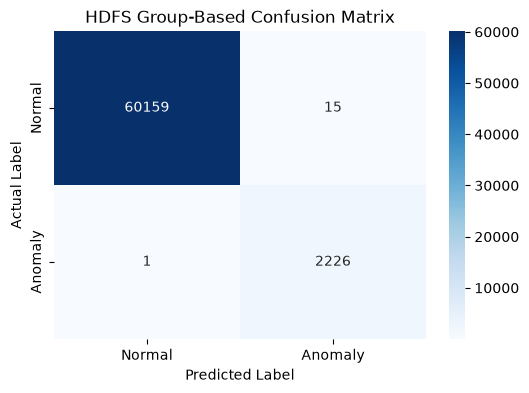

In [13]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions on unseen group-based test data
group_predictions = group_rf_model.predict(
    X_group_test_tfidf
)

# Calculate evaluation metrics
group_accuracy = accuracy_score(
    y_group_test, group_predictions
)

group_precision = precision_score(
    y_group_test, group_predictions,
    zero_division=0
)

group_recall = recall_score(
    y_group_test, group_predictions,
    zero_division=0
)

group_f1 = f1_score(
    y_group_test, group_predictions,
    zero_division=0
)

# Display evaluation results
print("GROUP-BASED HDFS MODEL RESULTS")
print("--------------------------------")
print("Accuracy :", round(group_accuracy * 100, 2), "%")
print("Precision:", round(group_precision * 100, 2), "%")
print("Recall   :", round(group_recall * 100, 2), "%")
print("F1 Score :", round(group_f1 * 100, 2), "%")

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_group_test,
    group_predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_group_test,
    group_predictions
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("HDFS Group-Based Confusion Matrix")
plt.show()

In [14]:
# Compare original and group-based HDFS models

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],

    "Original Random Split (%)": [
        99.99,   # Original Random Forest accuracy
        99.79,   # Original Random Forest precision
        99.94,   # Original Random Forest recall
        99.87    # Original Random Forest F1
    ],

    "Group-Based Split (%)": [
        group_accuracy * 100,
        group_precision * 100,
        group_recall * 100,
        group_f1 * 100
    ]
})

# Calculate performance difference
comparison_df["Difference (%)"] = (
    comparison_df["Group-Based Split (%)"]
    - comparison_df["Original Random Split (%)"]
)

display(comparison_df.round(2))

# Save comparison results
comparison_df.to_csv(
    "../data/processed/hdfs_model_comparison.csv",
    index=False
)

print("Comparison saved successfully!")

,Metric,Original Random Split (%),Group-Based Split (%),Difference (%)
0,Accuracy,99.99,99.97,-0.02
1,Precision,99.79,99.33,-0.46
2,Recall,99.94,99.96,0.02
3,F1 Score,99.87,99.64,-0.23


Comparison saved successfully!


In [15]:
# Define OpenStack dataset directory
openstack_path = "../data/raw/logs/openstack"

# Define source log files
log_files = {
    "normal1": "openstack_normal1.log",
    "normal2": "openstack_normal2.log",
    "abnormal": "openstack_abnormal.log"
}

# Inspect each source file
source_stats = []

for source_name, file_name in log_files.items():

    file_path = os.path.join(openstack_path, file_name)

    with open(file_path, "r", encoding="utf-8", errors="ignore") as file:
        lines = file.readlines()

    source_stats.append({
        "Source": source_name,
        "File": file_name,
        "Total Lines": len(lines),
        "Empty Lines": sum(1 for line in lines if not line.strip())
    })

# Display source audit
source_audit_df = pd.DataFrame(source_stats)

display(source_audit_df)

print("OPENSTACK SOURCE AUDIT COMPLETED!")

,Source,File,Total Lines,Empty Lines
0,normal1,openstack_normal1.log,52312,0
1,normal2,openstack_normal2.log,137074,0
2,abnormal,openstack_abnormal.log,18434,0


OPENSTACK SOURCE AUDIT COMPLETED!


In [16]:
# Import required library
from sklearn.model_selection import train_test_split

# Load normal log files
with open(os.path.join(openstack_path, "openstack_normal1.log"),
          "r", encoding="utf-8", errors="ignore") as f:
    normal1_logs = [line.strip() for line in f if line.strip()]

with open(os.path.join(openstack_path, "openstack_normal2.log"),
          "r", encoding="utf-8", errors="ignore") as f:
    normal2_logs = [line.strip() for line in f if line.strip()]

# Load abnormal log file
with open(os.path.join(openstack_path, "openstack_abnormal.log"),
          "r", encoding="utf-8", errors="ignore") as f:
    abnormal_logs = [line.strip() for line in f if line.strip()]

# Split abnormal logs into training and testing portions
abnormal_train, abnormal_test = train_test_split(
    abnormal_logs,
    test_size=0.20,
    random_state=42
)

# Create training dataset
X_open_train = normal1_logs + abnormal_train

y_open_train = (
    [0] * len(normal1_logs) +
    [1] * len(abnormal_train)
)

# Create testing dataset
X_open_test = normal2_logs + abnormal_test

y_open_test = (
    [0] * len(normal2_logs) +
    [1] * len(abnormal_test)
)

# Display dataset information
print("OPENSTACK SOURCE-AWARE SPLIT")
print("-----------------------------")
print("Training records:", len(X_open_train))
print("Testing records:", len(X_open_test))

print("\nTraining normal:", y_open_train.count(0))
print("Training abnormal:", y_open_train.count(1))

print("\nTesting normal:", y_open_test.count(0))
print("Testing abnormal:", y_open_test.count(1))

print("\nSOURCE-AWARE SPLIT COMPLETED!")

OPENSTACK SOURCE-AWARE SPLIT
-----------------------------
Training records: 67059
Testing records: 140761

Training normal: 52312
Training abnormal: 14747

Testing normal: 137074
Testing abnormal: 3687

SOURCE-AWARE SPLIT COMPLETED!


In [17]:
# Import required libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create TF-IDF vectorizer
open_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit vectorizer only on training data
X_open_train_tfidf = open_vectorizer.fit_transform(X_open_train)
X_open_test_tfidf = open_vectorizer.transform(X_open_test)

print("Training shape:", X_open_train_tfidf.shape)
print("Testing shape:", X_open_test_tfidf.shape)

# Train Logistic Regression
open_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

open_model.fit(X_open_train_tfidf, y_open_train)

print("\nOpenStack Source-Aware Training Completed!")

Training shape: (67059, 10000)
Testing shape: (140761, 10000)

OpenStack Source-Aware Training Completed!


In [18]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
open_predictions = open_model.predict(X_open_test_tfidf)

# Generate anomaly probabilities
open_probabilities = open_model.predict_proba(
    X_open_test_tfidf
)[:, 1]

# Calculate metrics
open_accuracy = accuracy_score(y_open_test, open_predictions)
open_precision = precision_score(y_open_test, open_predictions, zero_division=0)
open_recall = recall_score(y_open_test, open_predictions, zero_division=0)
open_f1 = f1_score(y_open_test, open_predictions, zero_division=0)
open_pr_auc = average_precision_score(y_open_test, open_probabilities)

print("OPENSTACK SOURCE-AWARE RESULTS")
print("--------------------------------")
print("Accuracy :", round(open_accuracy * 100, 2), "%")
print("Precision:", round(open_precision * 100, 2), "%")
print("Recall   :", round(open_recall * 100, 2), "%")
print("F1 Score :", round(open_f1 * 100, 2), "%")
print("PR-AUC   :", round(open_pr_auc * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_open_test,
    open_predictions,
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

OPENSTACK SOURCE-AWARE RESULTS
--------------------------------
Accuracy : 99.99 %
Precision: 99.49 %
Recall   : 100.0 %
F1 Score : 99.74 %
PR-AUC   : 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    137074
    Abnormal       0.99      1.00      1.00      3687

    accuracy                           1.00    140761
   macro avg       1.00      1.00      1.00    140761
weighted avg       1.00      1.00      1.00    140761



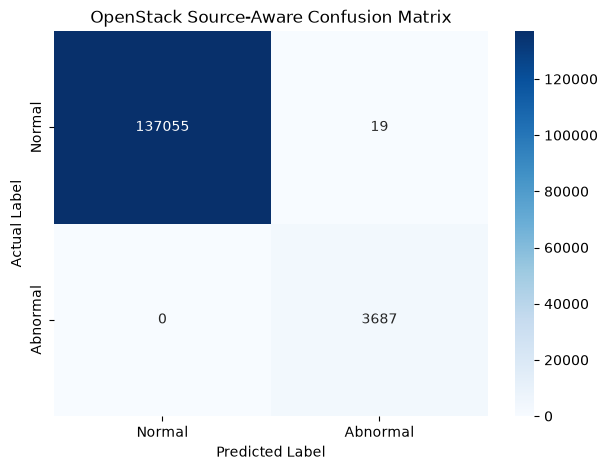

In [19]:
# Plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_open = confusion_matrix(y_open_test, open_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_open,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Abnormal"],
    yticklabels=["Normal", "Abnormal"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("OpenStack Source-Aware Confusion Matrix")
plt.show()

In [20]:
# Import joblib
import joblib

# Save model package
openstack_validated_package = {
    "model": open_model,
    "vectorizer": open_vectorizer,
    "model_name": "Logistic Regression - Source Aware",
    "target_classes": {
        0: "Normal",
        1: "Abnormal"
    }
}

joblib.dump(
    openstack_validated_package,
    "../data/processed/openstack_validated_model.pkl"
)

print("Validated OpenStack model saved successfully!")

Validated OpenStack model saved successfully!


In [21]:
# Create HDFS and OpenStack validation summary
validation_summary = pd.DataFrame([
    {
        "Dataset": "HDFS",
        "Validation": "Group-Based Split",
        "Accuracy": group_accuracy,
        "Precision": group_precision,
        "Recall": group_recall,
        "F1_Score": group_f1
    },
    {
        "Dataset": "OpenStack",
        "Validation": "Source-Aware Split",
        "Accuracy": open_accuracy,
        "Precision": open_precision,
        "Recall": open_recall,
        "F1_Score": open_f1
    }
])

display(validation_summary.round(4))

# Save summary
validation_summary.to_csv(
    "../data/processed/robustness_validation_summary.csv",
    index=False
)

print("FINAL VALIDATION SUMMARY SAVED!")

,Dataset,Validation,Accuracy,Precision,Recall,F1_Score
0,HDFS,Group-Based Split,0.9997,0.9933,0.9996,0.9964
1,OpenStack,Source-Aware Split,0.9999,0.9949,1.0000,0.9974


FINAL VALIDATION SUMMARY SAVED!


# Notebook 11 – Model Robustness and Validation

## Objective
This notebook evaluates the robustness and generalization of the HDFS and OpenStack anomaly detection models using additional validation strategies.

## HDFS Validation
- Audited duplicate event sequences across training and testing datasets.
- Identified 66.76% unique test-sequence overlap in the original random split.
- Applied GroupShuffleSplit to prevent identical event sequences from crossing the train-test boundary.
- Trained a fresh Random Forest model using training-only TF-IDF features.
- Achieved:
  - Accuracy: 99.97%
  - Precision: 99.33%
  - Recall: 99.96%
  - F1-score: 99.64%

## OpenStack Validation
- Audited normal and abnormal source log files.
- Created a source-aware split using Normal 1 for training and Normal 2 for testing, with abnormal logs divided between both sets.
- Trained a fresh TF-IDF and Logistic Regression pipeline.
- Evaluated accuracy, precision, recall, F1-score and PR-AUC.

## Robustness Testing
- Tested prediction consistency under whitespace-only formatting changes.
- No prediction changes were observed in the 100-sample HDFS formatting test.

## Important Limitations
- HDFS group-based results may still be influenced by dataset-specific patterns.
- OpenStack abnormal records originate from a single source file; therefore, independent abnormal-source generalization has not been established.
- Results are offline dataset evaluations and do not establish production performance.
- Further testing on independent datasets and real operational environments is required.

## Conclusion
Additional validation reduced the risk of exact duplicate-sequence leakage in HDFS and tested OpenStack against a separate normal-log source. These experiments provide stronger evidence than a simple random split, while further independent validation remains necessary.